# Train the leaf-disease segmentation model


## 1. Imports and settings

In [1]:
from pathlib import Path
import math
import os
import random

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
os.environ.setdefault("TF_GPU_ALLOCATOR", "cuda_malloc_async")
import tensorflow as tf

SEED = 42
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8
FROZEN_EPOCHS = 40
FINE_TUNE_EPOCHS = 100

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

I0000 00:00:1794600791.712404  141549 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
GPU available: True


## 2. Load the prepared datasets

In [2]:
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

def load_prepared_pairs(split_name):
    image_dir = PROCESSED_DIR / split_name / "images"
    mask_dir = PROCESSED_DIR / split_name / "masks"
    if not image_dir.exists() or not mask_dir.exists():
        raise FileNotFoundError(
            f"Prepared {split_name} folders were not found."
        )
    image_paths = sorted(image_dir.glob("*.png"))
    pairs = [
        (image_path, mask_dir / image_path.name)
        for image_path in image_paths
        if (mask_dir / image_path.name).exists()
    ]
    if len(pairs) != len(image_paths):
        raise RuntimeError(f"Some {split_name} images have no matching masks.")
    return pairs

train_pairs = load_prepared_pairs("train")
validation_pairs = load_prepared_pairs("validation")
test_pairs = load_prepared_pairs("test")

print("Training:  ", len(train_pairs))
print("Validation:", len(validation_pairs))
print("Test:      ", len(test_pairs))

Training:   411
Validation: 88
Test:       89


## 3. ResNet preprocessing, augmentation, and batches


In [3]:
train_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.90, 1.10), p=0.5),
    A.Rotate(limit=20, border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    A.RandomBrightnessContrast(
        brightness_limit=0.20, contrast_limit=0.0, p=0.5
    ),
])

def prepare_sample(pair, augment=False):
    image_path, mask_path = pair
    image = cv2.cvtColor(
        cv2.imread(str(image_path), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB
    )
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)[..., None]
    if augment:
        transformed = train_augmentation(image=image, mask=mask)
        image, mask = transformed["image"], transformed["mask"]

    image = tf.keras.applications.resnet50.preprocess_input(
        image.astype(np.float32)
    )
    return image, (mask > 127).astype(np.float32)

In [4]:
class SegmentationLoader(tf.keras.utils.Sequence):
    def __init__(self, pairs, batch_size=1, augment=False, shuffle=False):
        super().__init__()
        self.pairs = list(pairs)
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.indices = np.arange(len(self.pairs))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.indices) / self.batch_size)

    def __getitem__(self, index):
        start = index * self.batch_size
        batch_indices = self.indices[start:start + self.batch_size]
        samples = [
            prepare_sample(self.pairs[item], augment=self.augment)
            for item in batch_indices
        ]
        images, masks = zip(*samples)
        return np.stack(images), np.stack(masks)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

train_loader = SegmentationLoader(
    train_pairs, BATCH_SIZE, augment=True, shuffle=True
)
validation_loader = SegmentationLoader(validation_pairs, BATCH_SIZE)
test_loader = SegmentationLoader(test_pairs, BATCH_SIZE)

batch_images, batch_masks = train_loader[0]
print("Image batch:", batch_images.shape)
print("Mask batch: ", batch_masks.shape)

Image batch: (8, 256, 256, 3)
Mask batch:  (8, 256, 256, 1)


## 4. Dice + focal loss and metrics

In [5]:
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    total = tf.reduce_sum(y_true + y_pred, axis=axes)
    return tf.reduce_mean((2.0 * intersection + smooth) / (total + smooth))

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)

focal_loss = tf.keras.losses.BinaryFocalCrossentropy(
    apply_class_balancing=True, alpha=0.75, gamma=2.0
)

def dice_focal_loss(y_true, y_pred):
    return focal_loss(y_true, y_pred) + dice_loss(y_true, y_pred)

def iou_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true > 0.5, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    union = tf.reduce_sum(y_true + y_pred, axis=axes) - intersection
    return tf.reduce_mean((intersection + smooth) / (union + smooth))

## 5. Build a ResNet50 U-Net

ResNet50 supplies ImageNet-pretrained encoder features. The U-Net decoder learns to reconstruct the binary disease mask.

In [6]:
def decoder_block(x, skip, filters):
    x = tf.keras.layers.Conv2DTranspose(
        filters, 3, strides=2, padding="same"
    )(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.GroupNormalization(groups=8)(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.GroupNormalization(groups=8)(x)
    return tf.keras.layers.ReLU()(x)

def build_resnet_unet(input_shape=(256, 256, 3)):
    base_model = tf.keras.applications.ResNet50(
        input_shape=input_shape, include_top=False, weights="imagenet"
    )

    skip_layer_names = [
        "conv1_relu",       # 128 x 128
        "conv2_block3_out", # 64 x 64
        "conv3_block4_out", # 32 x 32
        "conv4_block6_out", # 16 x 16
    ]
    encoder_outputs = [base_model.get_layer(name).output for name in skip_layer_names]
    encoder_outputs.append(base_model.get_layer("conv5_block3_out").output)
    encoder = tf.keras.Model(base_model.input, encoder_outputs, name="resnet50_encoder")
    encoder.trainable = False

    inputs = tf.keras.Input(input_shape)
    s1, s2, s3, s4, x = encoder(inputs, training=False)
    x = decoder_block(x, s4, 256)
    x = decoder_block(x, s3, 128)
    x = decoder_block(x, s2, 64)
    x = decoder_block(x, s1, 32)
    x = tf.keras.layers.Conv2DTranspose(16, 3, strides=2, padding="same")(x)
    outputs = tf.keras.layers.Conv2D(1, 1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="resnet50_unet")
    return model, encoder

model, encoder = build_resnet_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_focal_loss,
    metrics=["binary_accuracy", dice_coefficient, dice_loss, iou_score],
)
model.summary()

I0000 00:00:1794600797.078576  141549 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1794600797.079871  141549 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4149 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "resnet50_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_encoder    │ [(None, 128, 128, │ 23,587,712 │ input_layer_1[0]… │
│ (Functional)        │ 64), (None, 64,   │            │                   │
│                     │ 64, 256), (None,  │            │                   │
│                     │ 32, 32, 512),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 1024), (None, 8,  │            │                   │
│                     │ 8, 2048)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  4,718,848 │ resnet50_encoder… │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 1280)             │            │ resnet50_encoder… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │  2,949,120 │ concatenate[0][0] │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 16, 16,    │        512 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 16, 16,    │          0 │ group_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │    589,824 │ re_lu[0][0]       │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 16, 16,    │          0 │ group_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │    295,040 │ re_lu_1[0][0]     │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 640)              │            │ resnet50_encoder… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │    737,280 │ concatenate_1[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_2[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ group_normalizat… │
│                     │ 128)              │            │                 

 Total params: 33,382,145 (127.34 MB)

 Trainable params: 9,794,433 (37.36 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 6. Train

Early stopping restores the weights from the epoch with the highest validation IoU. The best complete model is also saved in `models/`.

In [7]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
FROZEN_MODEL_PATH = MODEL_DIR / "resnet50_unet_frozen.keras"
MODEL_PATH = MODEL_DIR / "best_resnet50_unet.keras"

def make_callbacks(model_path):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            model_path, monitor="val_iou_score", mode="max", save_best_only=True
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_iou_score", mode="max", patience=10, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_iou_score", mode="max", factor=0.5, patience=4, min_lr=1e-6
        ),
    ]

# Stage 1: train only the decoder.
history_frozen = model.fit(
    train_loader,
    validation_data=validation_loader,
    epochs=FROZEN_EPOCHS,
    callbacks=make_callbacks(FROZEN_MODEL_PATH),
)

# Stage 2: fine-tune the final 80 encoder layers with a small learning rate.
encoder.trainable = True
for layer in encoder.layers[:-80]:
    layer.trainable = False
for layer in encoder.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
    loss=dice_focal_loss,
    metrics=["binary_accuracy", dice_coefficient, dice_loss, iou_score],
)

history_fine = model.fit(
    train_loader,
    validation_data=validation_loader,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=make_callbacks(MODEL_PATH),
)

history = {
    key: history_frozen.history.get(key, []) + history_fine.history.get(key, [])
    for key in set(history_frozen.history) | set(history_fine.history)
}

Epoch 1/40


I0000 00:00:1794600798.910649  141549 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1794600805.583521  141661 service.cc:153] XLA service 0x72063403f0a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794600805.583547  141661 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 13.0.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1794600805.834932  141661 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794600807.545327  141661 cuda_dnn.cc:461] Loaded cuDNN version 92400


 2/52 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - binary_accuracy: 0.6092 - dice_coefficient: 0.1698 - dice_loss: 0.8302 - iou_score: 0.0952 - loss: 0.8879  

I0000 00:00:1794600828.237339  141661 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


52/52 ━━━━━━━━━━━━━━━━━━━━ 55s 493ms/step - binary_accuracy: 0.6749 - dice_coefficient: 0.2705 - dice_loss: 0.7295 - iou_score: 0.2674 - loss: 0.7796 - val_binary_accuracy: 0.8613 - val_dice_coefficient: 0.3498 - val_dice_loss: 0.6502 - val_iou_score: 0.4436 - val_loss: 0.6950 - learning_rate: 1.0000e-04
Epoch 2/40
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - binary_accuracy: 0.8631 - dice_coefficient: 0.4016 - dice_loss: 0.5984 - iou_score: 0.4593 - loss: 0.6428 - val_binary_accuracy: 0.8995 - val_dice_coefficient: 0.4753 - val_dice_loss: 0.5247 - val_iou_score: 0.5392 - val_loss: 0.5730 - learning_rate: 1.0000e-04
Epoch 3/40
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - binary_accuracy: 0.8903 - dice_coefficient: 0.4820 - dice_loss: 0.5180 - iou_score: 0.5130 - loss: 0.5674 - val_binary_accuracy: 0.8833 - val_dice_coefficient: 0.5410 - val_dice_loss: 0.4590 - val_iou_score: 0.5301 - val_loss: 0.5076 - learning_rate: 1.0000e-04
Epoch 4/40
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - binary_accu

## 7. Plot training history

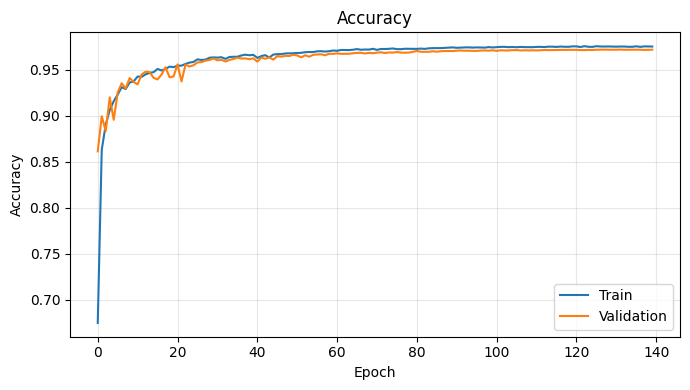

In [13]:
plt.figure(figsize=(7, 4))

plt.plot(history["binary_accuracy"], label="Train")
plt.plot(history["val_binary_accuracy"], label="Validation")

plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

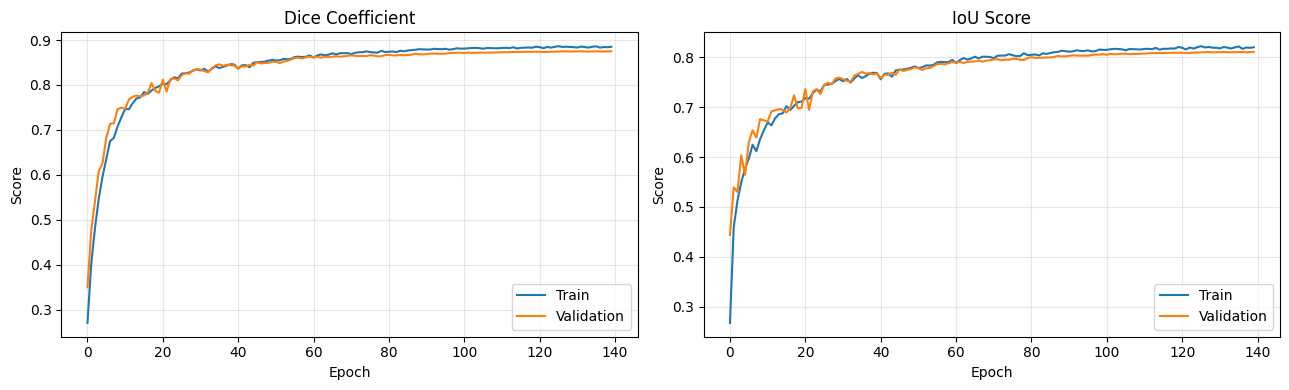

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

metrics = [
    ("dice_coefficient", "val_dice_coefficient", "Dice Coefficient"),
    ("iou_score", "val_iou_score", "IoU Score"),
]

for ax, (train_key, val_key, title) in zip(axes, metrics):
    ax.plot(history[train_key], label="Train")
    ax.plot(history[val_key], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

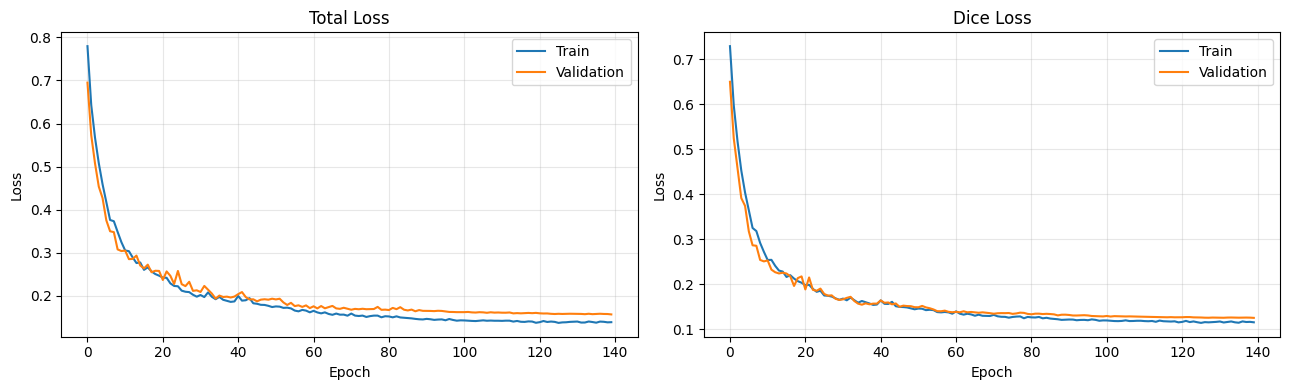

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

losses = [
    ("loss", "val_loss", "Total Loss"),
    ("dice_loss", "val_dice_loss", "Dice Loss"),
]

for ax, (train_key, val_key, title) in zip(axes, losses):
    ax.plot(history[train_key], label="Train")
    ax.plot(history[val_key], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 8. Select the threshold on validation data

Select the probability threshold using validation data only, then keep it fixed for the test set.

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step
Best threshold: 0.55
Best validation IoU: 0.8115


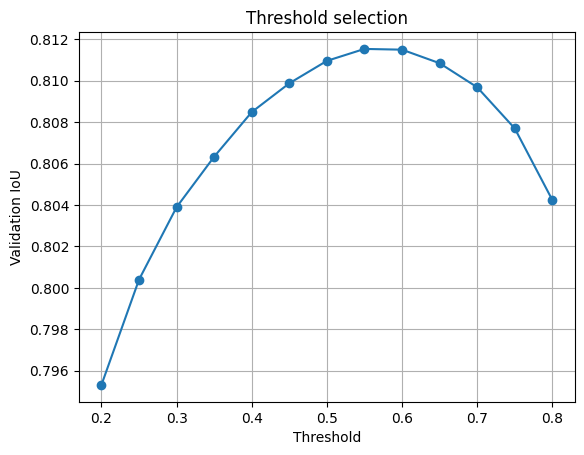

In [9]:
def collect_predictions(loader):
    probabilities = model.predict(loader, verbose=1)
    true_masks = np.concatenate(
        [loader[index][1] for index in range(len(loader))], axis=0
    )
    return true_masks, probabilities

def mean_iou_at_threshold(true_masks, probabilities, threshold, smooth=1e-6):
    predictions = probabilities > threshold
    true_masks = true_masks > 0.5
    axes = (1, 2, 3)
    intersection = np.sum(predictions & true_masks, axis=axes)
    union = np.sum(predictions | true_masks, axis=axes)
    return np.mean((intersection + smooth) / (union + smooth))

validation_true, validation_probabilities = collect_predictions(validation_loader)
thresholds = np.arange(0.20, 0.81, 0.05)
validation_ious = [
    mean_iou_at_threshold(validation_true, validation_probabilities, threshold)
    for threshold in thresholds
]
BEST_THRESHOLD = float(thresholds[np.argmax(validation_ious)])

print(f"Best threshold: {BEST_THRESHOLD:.2f}")
print(f"Best validation IoU: {max(validation_ious):.4f}")
plt.plot(thresholds, validation_ious, marker="o")
plt.xlabel("Threshold")
plt.ylabel("Validation IoU")
plt.title("Threshold selection")
plt.grid(True)
plt.show()

## 9. Final test evaluation


In [10]:
test_results = model.evaluate(test_loader, return_dict=True)
for name, value in test_results.items():
    print(f"{name} at threshold 0.50: {value:.4f}")

test_true, test_probabilities = collect_predictions(test_loader)
tuned_test_iou = mean_iou_at_threshold(
    test_true, test_probabilities, BEST_THRESHOLD
)
print(f"Test IoU at threshold {BEST_THRESHOLD:.2f}: {tuned_test_iou:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 723ms/step - binary_accuracy: 0.9737 - dice_coefficient: 0.8795 - dice_loss: 0.1205 - iou_score: 0.8169 - loss: 0.1447
binary_accuracy at threshold 0.50: 0.9737
dice_coefficient at threshold 0.50: 0.8795
dice_loss at threshold 0.50: 0.1205
iou_score at threshold 0.50: 0.8169
loss at threshold 0.50: 0.1447
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 382ms/step
Test IoU at threshold 0.55: 0.8199


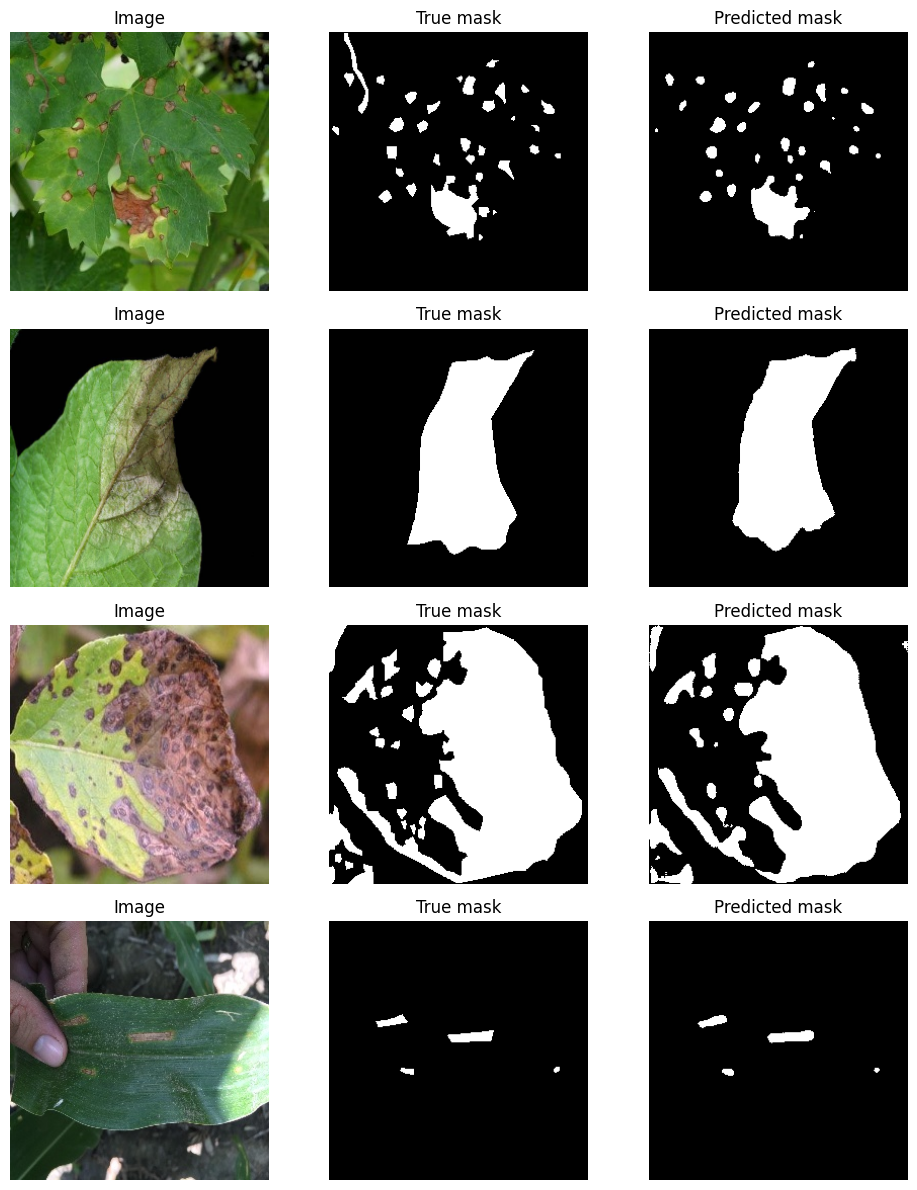

In [11]:
# Display four test predictions.
images, true_masks = test_loader[0]
predicted_masks = model.predict(images, verbose=0) > BEST_THRESHOLD
count = min(4, len(images))

def restore_resnet_image(image):
    image = image.copy()
    image[..., 0] += 103.939
    image[..., 1] += 116.779
    image[..., 2] += 123.680
    image = image[..., ::-1]
    return np.clip(image / 255.0, 0, 1)

fig, axes = plt.subplots(count, 3, figsize=(10, 3 * count))
for row in range(count):
    axes[row, 0].imshow(restore_resnet_image(images[row]))
    axes[row, 0].set_title("Image")
    axes[row, 1].imshow(true_masks[row].squeeze(), cmap="gray")
    axes[row, 1].set_title("True mask")
    axes[row, 2].imshow(predicted_masks[row].squeeze(), cmap="gray")
    axes[row, 2].set_title("Predicted mask")
    for axis in axes[row]:
        axis.axis("off")
plt.tight_layout()
plt.show()